# 04 - SHAP explainability (FD001, XGBoost)

Explains the XGBoost RUL model from `02_baselines` with SHAP.

- **Global**: which sensors drive RUL predictions across all engines.
- **Local**: why one specific engine got its predicted RUL.

`TreeExplainer` gives exact SHAP values for tree models: for every engine,
`base value + sum of SHAP values = predicted RUL`.

A **positive** SHAP value pushes predicted RUL **up** (healthier), a **negative** one pushes it **down** (closer to failure).

## 1. Load data and build summary features (same as 02_baselines)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from xgboost import XGBRegressor

d = np.load("../data/processed/fd001_windows.npz")
X_tr, y_tr = d["X_tr"], d["y_tr"]
X_test, y_test_raw = d["X_test"], d["y_test"]   # uncapped true RUL
sensors = list(d["features"])

def summarize(X):
    t = np.arange(X.shape[1])
    slope = ((X - X.mean(1, keepdims=True)) * (t - t.mean())[None, :, None]).sum(1) / ((t - t.mean()) ** 2).sum()
    return np.concatenate([X[:, -1], X.mean(1), X.std(1), X.min(1), X.max(1), slope], axis=1)

STATS = ["last", "mean", "std", "min", "max", "slope"]
feat_names = [f"{s}_{st}" for st in STATS for s in sensors]   # same column order as summarize()

F_tr, F_test = summarize(X_tr), summarize(X_test)
print(F_tr.shape, F_test.shape, len(feat_names))

/Users/chintansood7/miniforge3/envs/aerohealth/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(14241, 90) (100, 90) 90


## 2. Train XGBoost (same hyperparameters as 02_baselines)

In [2]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                   subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)
xgb.fit(F_tr, y_tr)
pred = xgb.predict(F_test)
print("test RMSE (uncapped):", round(float(np.sqrt(np.mean((y_test_raw - pred) ** 2))), 2))

test RMSE (uncapped): 14.09


## 3. SHAP values + additivity check

In [3]:
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(F_test)            # (100 engines, 90 features)
base = float(explainer.expected_value)
print("SHAP matrix:", sv.shape, "| base value (average prediction):", round(base, 2))
print("max |pred - (base + sum SHAP)|:", float(np.abs(pred - (base + sv.sum(1))).max()))

expl = shap.Explanation(values=sv, base_values=np.full(len(sv), base),
                        data=F_test, feature_names=feat_names)

SHAP matrix: (100, 90) | base value (average prediction): 80.77
max |pred - (base + sum SHAP)|: 0.00016021728515625


## 4. Global: top features (beeswarm)
Each dot is one test engine. Colour = feature value (red high, blue low); x-position = effect on predicted RUL.

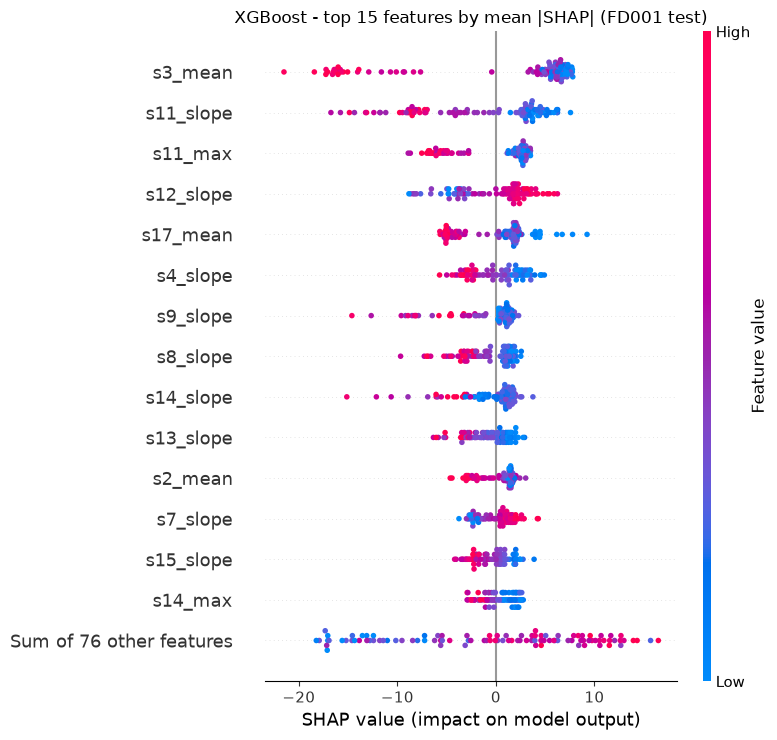

In [4]:
shap.plots.beeswarm(expl, max_display=15, show=False)
plt.title("XGBoost - top 15 features by mean |SHAP| (FD001 test)")
plt.tight_layout()
plt.savefig("../results/shap_beeswarm_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Global: importance per sensor
Sum of mean |SHAP| over the 6 statistics of each sensor, i.e. how much each physical sensor matters overall.

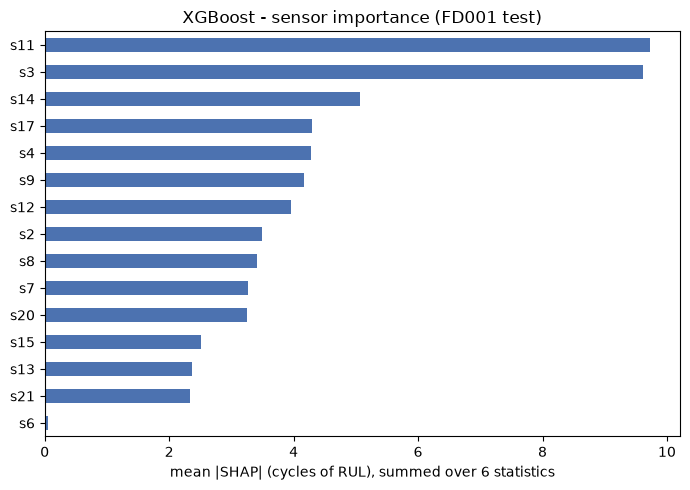

Importance by statistic type:
slope    43.3 %
mean     26.1 %
max      15.6 %
min       8.5 %
std       5.5 %
last      1.0 %
dtype: str


In [5]:
imp = pd.DataFrame(np.abs(sv).mean(0).reshape(len(STATS), len(sensors)), index=STATS, columns=sensors)
sensor_imp = imp.sum(axis=0).sort_values()
stat_imp = imp.sum(axis=1).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
sensor_imp.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("mean |SHAP| (cycles of RUL), summed over 6 statistics")
ax.set_title("XGBoost - sensor importance (FD001 test)")
plt.tight_layout()
plt.savefig("../results/shap_sensor_importance_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

print("Importance by statistic type:")
print((stat_imp / stat_imp.sum() * 100).round(1).astype(str) + " %")

## 6. Local: explain individual engines
Most at-risk engine (lowest predicted RUL) vs healthiest (highest predicted RUL).
Row *i* of the test set is test engine *i+1* (windows are built with `groupby("engine")`).

Engine 68 (most at risk): predicted RUL 7.0, true RUL 8


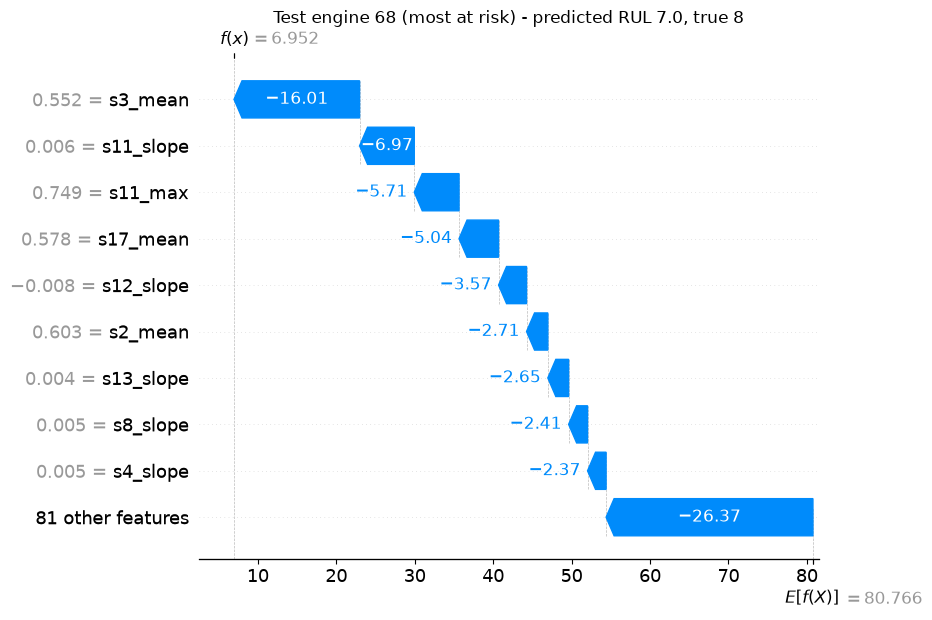

Engine 85 (healthiest): predicted RUL 130.3, true RUL 118


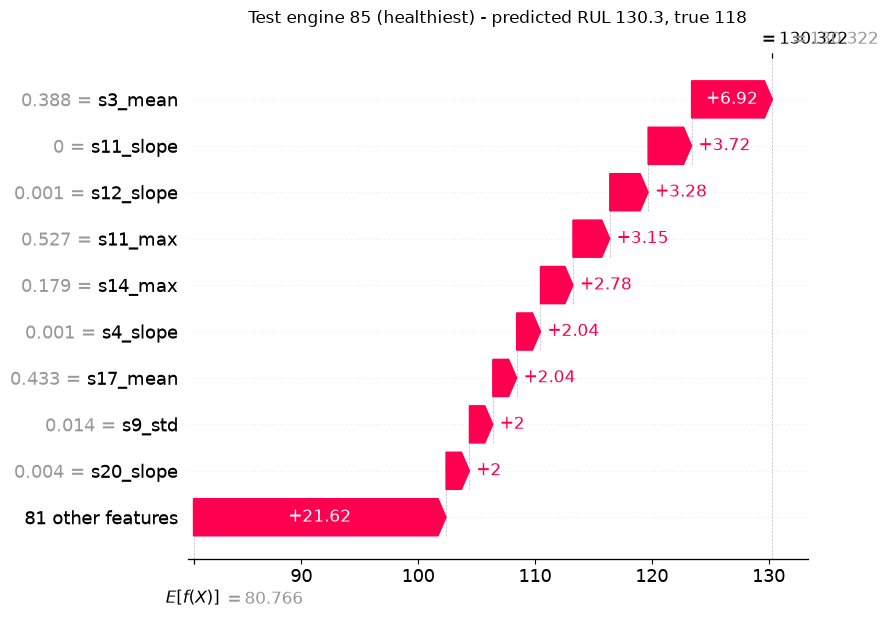

In [6]:
for label, i in [("most at risk", int(pred.argmin())), ("healthiest", int(pred.argmax()))]:
    print(f"Engine {i+1} ({label}): predicted RUL {pred[i]:.1f}, true RUL {y_test_raw[i]:.0f}")
    shap.plots.waterfall(expl[i], max_display=10, show=False)
    plt.title(f"Test engine {i+1} ({label}) - predicted RUL {pred[i]:.1f}, true {y_test_raw[i]:.0f}")
    plt.savefig(f"../results/shap_waterfall_engine{i+1}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 7. Per-engine summary: top 3 drivers
Saved to `results/shap_top_drivers_xgb.csv` for the Streamlit dashboard.

In [7]:
rows = []
for i in range(len(sv)):
    top = np.argsort(-np.abs(sv[i]))[:3]
    row = {"engine": i + 1, "pred_RUL": round(float(pred[i]), 1), "true_RUL": int(y_test_raw[i]),
           "abs_error": round(abs(float(pred[i]) - float(y_test_raw[i])), 1)}
    for k, j in enumerate(top, 1):
        row[f"driver{k}"] = feat_names[j]
        row[f"driver{k}_shap"] = round(float(sv[i, j]), 1)
    rows.append(row)

drivers = pd.DataFrame(rows)
drivers.to_csv("../results/shap_top_drivers_xgb.csv", index=False)
drivers.sort_values("pred_RUL").head(10)

,engine,pred_RUL,true_RUL,abs_error,driver1,driver1_shap,driver2,driver2_shap,driver3,driver3_shap
67,68,7.0,8,1.0,s3_mean,-16.0,s11_slope,-7.0,s11_max,-5.7
33,34,7.2,7,0.2,s3_mean,-17.2,s11_slope,-8.5,s11_max,-7.0
75,76,8.0,10,2.0,s3_mean,-16.0,s11_slope,-7.2,s11_max,-5.6
81,82,8.3,9,0.7,s3_mean,-16.6,s11_slope,-9.8,s11_max,-6.4
80,81,8.3,8,0.3,s3_mean,-17.1,s11_slope,-7.2,s11_max,-6.3
30,31,9.1,8,1.1,s3_mean,-17.3,s11_slope,-7.7,s11_max,-6.0
19,20,11.1,16,4.9,s3_mean,-16.5,s11_slope,-8.5,s11_max,-6.7
41,42,12.2,10,2.2,s3_mean,-16.0,s11_slope,-9.0,s11_max,-5.1
48,49,12.6,21,8.4,s3_mean,-16.3,s11_slope,-8.5,s11_max,-6.5
55,56,16.8,15,1.8,s3_mean,-18.4,s11_max,-7.5,s11_slope,-7.1
